# Laboratorio 4: Problema Inverso en el Modelo SIR: Calibración y Sesgo de Discretización

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nabw/UNA-taller/blob/main/notebooks/solucion/04_calibracion_problema_inverso.ipynb)


## 1. Introducción: El Problema Inverso en Ciencia de Datos

En los laboratorios anteriores abordamos el **problema directo**: dados los parámetros físicos $(\beta, \gamma)$ y las condiciones iniciales, integramos numéricamente el sistema diferencial para calcular la trayectoria temporal $I(t)$.

En la práctica de la ciencia de datos y la epidemiología cuantitativa, la situación es la opuesta: se tiene acceso a una serie temporal de observaciones clínicas con ruido $I^{\text{obs}}_k$ en los instantes $t_k$, y se desea resolver el **problema inverso**: estimar el vector de parámetros generativos $\theta = (\beta, \gamma)$ que mejor describe los datos observados.

### El Fenómeno del Sesgo de Discretización (Discretization Bias)

Todo algoritmo de calibración optimiza los parámetros evaluando repetidamente un simulador numérico hacia adelante. Para estudiar y evidenciar con rigor este fenómeno, es indispensable utilizar un método numérico con **paso temporal $\Delta t$ controlado** (como el integrador IMEX conservativo del Laboratorio 2), en lugar de un resolvedor adaptativo de paso variable. Al controlar directamente el valor de $\Delta t$, podemos cuantificar cómo el error de truncamiento numérico del simulador es compensado artificialmente por el optimizador, desplazando los estimadores $\hat{\beta}(\Delta t)$ y $\hat{\gamma}(\Delta t)$ lejos de sus valores verdaderos continuos $\beta^*$ y $\gamma^*$.

## Objetivos de Aprendizaje

1. Formular computacionalmente la función de pérdida por mínimos cuadrados $L(\beta, \gamma)$ con simulación e interpolación.
2. Explorar y mapear la superficie de pérdida bidimensional mediante un gráfico de contornos.
3. Implementar la calibración de parámetros utilizando el algoritmo Nelder-Mead y registrar la trayectoria del símplex.
4. Ejecutar un experimento controlado evaluando $\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$ para cuantificar rigurosamente el sesgo de discretización sobre $\hat{\beta}$ y $\hat{R}_0$.
5. Analizar el impacto de este sesgo numérico en la toma de decisiones de salud pública y realizar el cierre metodológico del taller.


In [1]:
# Celda de configuración y librerías científicas autocontenidas
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
from typing import Any
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.integrate import solve_ivp

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 13,
    "lines.linewidth": 2.0,
    "grid.alpha": 0.4
})

# --------------------------------------------------------------------------
# Funciones auxiliares autocontenidas para integración y datos sintéticos
# --------------------------------------------------------------------------
def sir_imex_integrador(
    beta: float,
    gamma: float,
    dt: float,
    T: float,
    S0: float = 0.99,
    I0: float = 0.01
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """Integrador IMEX conservativo para el modelo SIR."""
    n_steps = int(np.round(T / dt))
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    S = np.zeros(n_steps + 1, dtype=np.float64)
    I = np.zeros(n_steps + 1, dtype=np.float64)
    R = np.zeros(n_steps + 1, dtype=np.float64)
    S[0], I[0], R[0] = S0, I0, 1.0 - S0 - I0

    for n in range(n_steps):
        contagio = dt * beta * S[n] * I[n]
        S[n + 1] = S[n] - contagio
        I[n + 1] = (I[n] + contagio) / (1.0 + dt * gamma)
        R[n + 1] = R[n] + dt * gamma * I[n + 1]

    return t, S, I, R

def generar_observaciones_referencia(
    beta_true: float = 0.4,
    gamma_true: float = 0.1,
    S0: float = 0.99,
    I0: float = 0.01,
    T: float = 50.0,
    sigma: float = 0.02,
    seed: int = 42
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Genera observaciones sintéticas con ruido Gaussiano."""
    def sir_ode(t, y):
        s, i, _ = y
        return [-beta_true * s * i, beta_true * s * i - gamma_true * i, gamma_true * i]

    sol = solve_ivp(
        sir_ode, (0.0, T), [S0, I0, 1.0 - S0 - I0],
        t_eval=np.linspace(0.0, T, 5001), method="RK45", rtol=1e-10, atol=1e-12
    )
    t_obs = np.arange(0.0, T + 1.0, 1.0)
    I_clean = np.interp(t_obs, sol.t, sol.y[1])
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, size=I_clean.shape)
    I_noisy = np.maximum(0.0, I_clean + noise)
    return t_obs, I_clean, I_noisy

t_obs, I_clean, I_obs = generar_observaciones_referencia()
print(f"Datos sintéticos generados: {len(t_obs)} observaciones diarias.")


Datos sintéticos generados: 51 observaciones diarias.


## 2. Formulación de la Función de Pérdida por Mínimos Cuadrados

Buscamos el vector de parámetros $\theta = (\beta, \gamma)$ que minimice la discrepancia cuadrática entre la solución numérica simulada $I^{\text{sim}}(t_k; \theta)$ y las observaciones clínicas $I^{\text{obs}}_k$:

$$L(\beta, \gamma) = \sum_{k=0}^M \left( I^{\text{sim}}(t_k; \beta, \gamma) - I^{\text{obs}}_k \right)^2$$

### Flujo de Cálculo de la Función de Pérdida

El cómputo sigue una secuencia de tres etapas lógicas directas:
1. **Validación de parámetros**: Verificar que $\beta > 0$ y $\gamma > 0$. Si se reciben valores no positivos, la función debe lanzar un `ValueError` (los parámetros físicos y epidemiológicos deben ser estrictamente positivos; el optimizador debe operar sobre configuraciones admisibles).
2. **Simulación temporal**: A partir de $(\beta, \gamma)$, simular la trayectoria hacia adelante usando el integrador `sir_imex_integrador` con el paso temporal $\Delta t_{\text{sim}}$ hasta $T = t_{\text{obs}}[-1]$:
   ```python
   t_sim, _, I_sim, _ = sir_imex_integrador(beta, gamma, dt_sim, T_final, S0, I0)
   ```
3. **Interpolación y cálculo del error**: Interpolar la trayectoria simulada sobre los instantes de observación $t_{\text{obs}}$ y calcular la suma de residuos cuadráticos:
   ```python
   I_interp = np.interp(t_obs, t_sim, I_sim)
   loss = float(np.sum((I_interp - I_obs) ** 2))
   ```

### Especificación de la Función a Implementar
- **Nombre**: `funcion_perdida(theta, t_obs, I_obs, dt_sim=0.10, S0=0.99, I0=0.01)`
- **Parámetros de entrada**:
  - `theta`: vector o lista de 2 elementos `[beta, gamma]`.
  - `t_obs: np.ndarray`: arreglo 1D con los instantes temporales de las observaciones.
  - `I_obs: np.ndarray`: arreglo 1D con las observaciones clínicas ruidosas.
  - `dt_sim: float = 0.10`: paso temporal del integrador IMEX hacia adelante.
  - `S0: float = 0.99, I0: float = 0.01`: condiciones iniciales de simulación.
- **Salida esperada**: Un número escalar `float` con el valor de la pérdida $L(\beta, \gamma)$.


In [2]:
def funcion_perdida(
    theta: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> float:
    """
    Calcula la suma de errores cuadráticos entre la simulación SIR y las observaciones.
    """
    beta, gamma = float(theta[0]), float(theta[1])
    if beta <= 0.0 or gamma <= 0.0:
        raise ValueError(f"Parámetros no físicos: beta={beta}, gamma={gamma} deben ser estrictamente positivos.")

    T_final = float(t_obs[-1])
    t_sim, _, I_sim, _ = sir_imex_integrador(beta, gamma, dt_sim, T_final, S0, I0)

    # Interpolar sobre los tiempos de observación
    I_interp = np.interp(t_obs, t_sim, I_sim)
    residuos = I_interp - I_obs
    loss = float(np.sum(residuos ** 2))
    return loss


In [3]:
# Pruebas de validación para funcion_perdida
loss_true = funcion_perdida([0.4, 0.1], t_obs, I_obs, dt_sim=0.10)
assert isinstance(loss_true, float), "La pérdida debe retornar un número float."
assert loss_true < 0.1, f"La pérdida en los parámetros verdaderos debe ser pequeña, obtenida: {loss_true}"

# Verificar que parámetros no positivos lanzan ValueError
try:
    funcion_perdida([-0.1, 0.1], t_obs, I_obs)
    assert False, "Debió lanzar ValueError ante beta no positivo."
except ValueError:
    pass

try:
    funcion_perdida([0.4, -0.05], t_obs, I_obs)
    assert False, "Debió lanzar ValueError ante gamma no positivo."
except ValueError:
    pass

print(f"Validación de funcion_perdida: EXITOSA (pérdida en theta*: {loss_true:.5f}).")


Validación de funcion_perdida: EXITOSA (pérdida en theta*: 0.01204).


## 3. Mapeo del Paisaje de Pérdida (Rejilla Bidimensional)

Para analizar la convexidad local, la presencia de valles y la correlación entre parámetros, evaluamos la función de costo sobre una rejilla regular de prueba en el plano $(\beta, \gamma)$:
- $\beta \in [0.20, 0.60]$
- $\gamma \in [0.04, 0.20]$

Para comprender cómo las estructuras contiguas de memoria en C y las operaciones vectorizadas de NumPy permiten acelerar estas evaluaciones masivas de pérdida en más de $50\times$ frente a bucles tradicionales, consulta el [Apéndice Teórico: Vectorización y Rendimiento en NumPy](https://github.com/nabw/UNA-taller/blob/main/appendix/vectorizacion_numpy.md).

### Especificación de la Función a Implementar
- **Nombre**: `evaluar_malla_perdida(beta_vals, gamma_vals, t_obs, I_obs, dt_sim=0.10, S0=0.99, I0=0.01)`
- **Parámetros de entrada**:
  - `beta_vals: np.ndarray`: arreglo 1D con los valores de $\beta$ (longitud $N_\beta$).
  - `gamma_vals: np.ndarray`: arreglo 1D con los valores de $\gamma$ (longitud $N_\gamma$).
  - `t_obs, I_obs, dt_sim, S0, I0`: argumentos pasados a `funcion_perdida`.
- **Salida esperada**: Arreglo 2D (`np.ndarray`) de dimensiones $(N_\gamma, N_\beta)$ donde el elemento `[i, j]` contiene la pérdida $L(\beta_j, \gamma_i)$.


In [4]:
def evaluar_malla_perdida(
    beta_vals: np.ndarray,
    gamma_vals: np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01
) -> np.ndarray:
    """
    Evalúa la pérdida sobre una rejilla bidimensional regular de parámetros.
    """
    n_gamma = len(gamma_vals)
    n_beta = len(beta_vals)
    L_grid = np.zeros((n_gamma, n_beta), dtype=np.float64)

    for i in range(n_gamma):
        g = float(gamma_vals[i])
        for j in range(n_beta):
            b = float(beta_vals[j])
            L_grid[i, j] = funcion_perdida([b, g], t_obs, I_obs, dt_sim, S0, I0)

    return L_grid


Validación y graficación de evaluar_malla_perdida: EXITOSA.


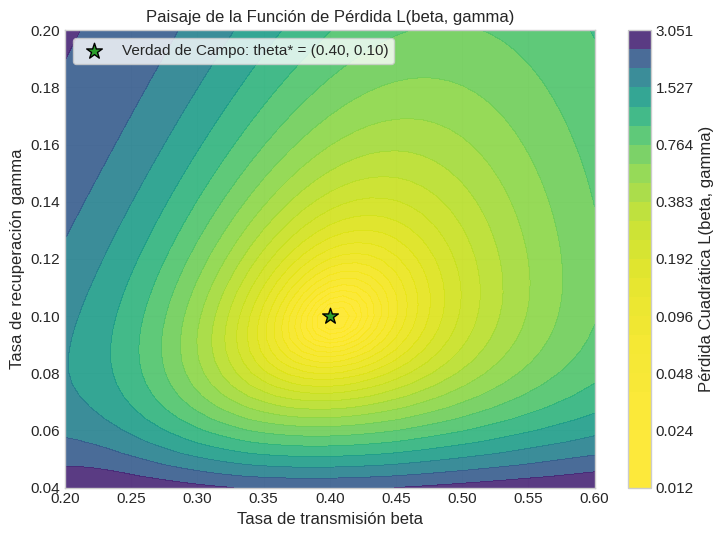

In [5]:
# Pruebas de validación y visualización gráfica del paisaje de pérdida
b_grid = np.linspace(0.20, 0.60, 41)
g_grid = np.linspace(0.04, 0.20, 41)
L_map = evaluar_malla_perdida(b_grid, g_grid, t_obs, I_obs, dt_sim=0.10)

assert L_map.shape == (len(g_grid), len(b_grid)), f"Forma esperada ({len(g_grid)}, {len(b_grid)}), obtenida {L_map.shape}"
assert np.all(L_map >= 0.0), "Todos los valores de pérdida deben ser positivos."

# Graficar de inmediato el mapa de contornos de la superficie de pérdida
fig, ax = plt.subplots(figsize=(7.5, 5.5))
B_mesh, G_mesh = np.meshgrid(b_grid, g_grid)
levels = np.geomspace(np.min(L_map) + 1e-4, np.max(L_map), 25)
cs = ax.contourf(B_mesh, G_mesh, L_map, levels=levels, cmap="viridis_r", alpha=0.9)
cbar = fig.colorbar(cs, ax=ax)
cbar.set_label("Pérdida Cuadrática L(beta, gamma)")
ax.scatter([0.40], [0.10], color="#2ca02c", s=140, marker="*", edgecolor="black", label="Verdad de Campo: theta* = (0.40, 0.10)", zorder=4)
ax.set_title("Paisaje de la Función de Pérdida L(beta, gamma)")
ax.set_xlabel("Tasa de transmisión beta")
ax.set_ylabel("Tasa de recuperación gamma")
ax.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

print("Validación y graficación de evaluar_malla_perdida: EXITOSA.")


## 4. Calibración con el Algoritmo Símplex de Nelder-Mead

El algoritmo de Nelder-Mead (1965) es un método de optimización heurístico libre de derivadas. En cada iteración, actualiza dinámicamente un polígono de $d+1$ vértices en $\mathbb{R}^d$ (un triángulo para $d=2$) mediante operaciones de reflexión, expansión y contracción.

Para conocer la formulación geométrica completa de Nelder-Mead y ejemplos mínimos reproducibles con SciPy, consulta el [Apéndice Técnico: Optimización Libre de Derivadas con Nelder-Mead en SciPy](https://github.com/nabw/UNA-taller/blob/main/appendix/optimizacion_nelder_mead.md).

> **Sugerencia de implementación:** Para pasar `t_obs`, `I_obs` y demás parámetros fijos al optimizador, define una función interna `def objective(theta): return funcion_perdida(theta, t_obs, I_obs, dt_sim, S0, I0)` y pásala directamente como primer argumento a `minimize(objective, x0=np.array(theta_init, dtype=np.float64), method="Nelder-Mead", callback=..., options={"maxiter": 500, "xatol": 1e-6, "fatol": 1e-6})`.

### Especificación de la Función a Implementar
- **Nombre**: `calibrar_sir(theta_init, t_obs, I_obs, dt_sim=0.10, S0=0.99, I0=0.01, track_history=True)`
- **Parámetros de entrada**:
  - `theta_init`: tupla o lista `[beta_0, gamma_0]` con el punto de partida del optimizador.
  - `t_obs, I_obs, dt_sim, S0, I0`: datos y configuración de simulación.
  - `track_history: bool = True`: si es `True`, registra la lista de posiciones del símplex mediante `callback`.
- **Salida esperada**: Un diccionario `dict[str, Any]` con las siguientes claves exactas:
  - `'theta_hat'`: arreglo `np.ndarray` con `[beta_hat, gamma_hat]`.
  - `'beta_hat'`: valor `float` de $\hat{\beta}$.
  - `'gamma_hat'`: valor `float` de $\hat{\gamma}$.
  - `'R0_hat'`: valor `float` de $\hat{R}_0 = \hat{\beta} / \hat{\gamma}$.
  - `'loss_val'`: valor `float` de la pérdida en el óptimo encontrado (`res.fun`).
  - `'success'`: booleano `bool` que indica si la optimización convergió exitosamente.
  - `'iterations'`: entero `int` con el total de iteraciones (`res.nit`).
  - `'history'`: arreglo 2D `np.ndarray` de dimensiones $(K, 2)$ con los puntos recorridos.


In [6]:
def calibrar_sir(
    theta_init: tuple[float, float] | list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    dt_sim: float = 0.10,
    S0: float = 0.99,
    I0: float = 0.01,
    track_history: bool = True
) -> dict[str, Any]:
    """
    Calibra beta y gamma minimizando la función de pérdida con Nelder-Mead.
    """
    history = [np.array(theta_init, dtype=np.float64).copy()]

    def callback(xk):
        history.append(np.array(xk, dtype=np.float64).copy())

    def objective(theta):
        return funcion_perdida(theta, t_obs, I_obs, dt_sim, S0, I0)

    res = minimize(
        objective,
        x0=np.array(theta_init, dtype=np.float64),
        method="Nelder-Mead",
        callback=callback if track_history else None,
        options={"maxiter": 500, "xatol": 1e-6, "fatol": 1e-6, "disp": False}
    )

    b_hat, g_hat = float(res.x[0]), float(res.x[1])
    r0_hat = b_hat / g_hat if g_hat > 0.0 else np.nan

    return {
        "theta_hat": res.x,
        "beta_hat": b_hat,
        "gamma_hat": g_hat,
        "R0_hat": r0_hat,
        "loss_val": float(res.fun),
        "success": bool(res.success),
        "iterations": int(res.nit),
        "history": np.array(history, dtype=np.float64)
    }


In [7]:
# Pruebas de validación para calibrar_sir
calib_test = calibrar_sir([0.2, 0.2], t_obs, I_obs, dt_sim=0.10)
assert calib_test["success"], "La optimización de Nelder-Mead debió converger exitosamente."
assert np.isclose(calib_test["beta_hat"], 0.4, atol=0.03), f"beta estimada lejana: {calib_test['beta_hat']}"
assert np.isclose(calib_test["gamma_hat"], 0.1, atol=0.02), f"gamma estimada lejana: {calib_test['gamma_hat']}"
print(f"Validación de calibrar_sir: EXITOSA (beta_hat: {calib_test['beta_hat']:.4f}, gamma_hat: {calib_test['gamma_hat']:.4f}).")


Validación de calibrar_sir: EXITOSA (beta_hat: 0.4046, gamma_hat: 0.0991).


## 5. Visualización del Descenso del Símplex sobre el Paisaje de Costo

Superponemos la trayectoria completa seguida por el símplex de Nelder-Mead desde el punto inicial $\theta_0 = (0.20, 0.20)$ hasta el óptimo estimado, contrastada con el valor verdadero continuo $\theta^* = (0.40, 0.10)$.


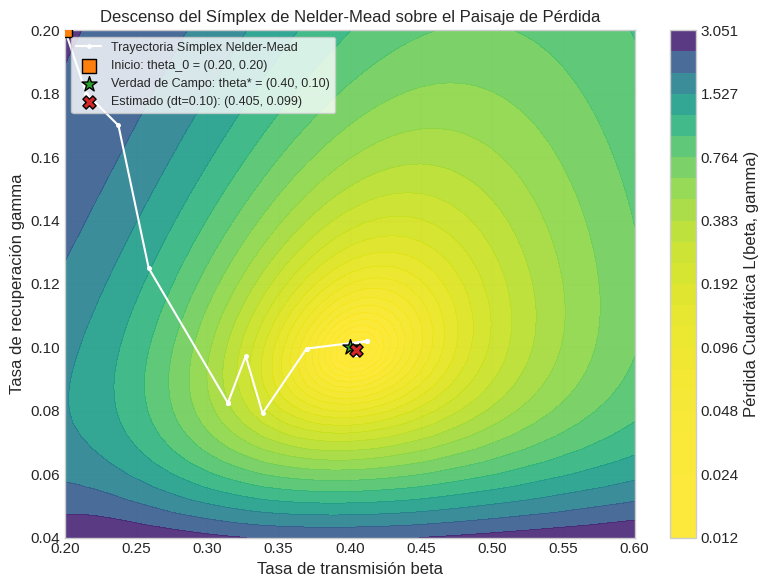

In [8]:
calib_init = calibrar_sir([0.20, 0.20], t_obs, I_obs, dt_sim=0.10, track_history=True)
hist = calib_init["history"]

fig, ax = plt.subplots(figsize=(8, 6))
B_mesh, G_mesh = np.meshgrid(b_grid, g_grid)
levels = np.geomspace(np.min(L_map) + 1e-4, np.max(L_map), 25)
cs = ax.contourf(B_mesh, G_mesh, L_map, levels=levels, cmap="viridis_r", alpha=0.9)
cbar = fig.colorbar(cs, ax=ax)
cbar.set_label("Pérdida Cuadrática L(beta, gamma)")

# Graficar trayectoria del símplex
ax.plot(hist[:, 0], hist[:, 1], 'w.-', linewidth=1.5, markersize=5, label="Trayectoria Símplex Nelder-Mead", zorder=3)
ax.scatter([0.20], [0.20], color="#ff7f0e", s=90, marker="s", edgecolor="black", label="Inicio: theta_0 = (0.20, 0.20)", zorder=4)
ax.scatter([0.40], [0.10], color="#2ca02c", s=130, marker="*", edgecolor="black", label="Verdad de Campo: theta* = (0.40, 0.10)", zorder=4)
ax.scatter([calib_init['beta_hat']], [calib_init['gamma_hat']], color="#d62728", s=90, marker="X", edgecolor="black", label=f"Estimado (dt=0.10): ({calib_init['beta_hat']:.3f}, {calib_init['gamma_hat']:.3f})", zorder=4)

ax.set_title("Descenso del Símplex de Nelder-Mead sobre el Paisaje de Pérdida")
ax.set_xlabel("Tasa de transmisión beta")
ax.set_ylabel("Tasa de recuperación gamma")
ax.legend(frameon=True, loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()


## 6. Experimento Sistemático: El Sesgo de Discretización

¿Qué ocurre si ajustamos el modelo SIR utilizando diferentes pasos temporales?

Evaluamos la calibración para una colección sistemática de pasos:

$$\Delta t \in [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]$$

Para cada $\Delta t$, registramos los estimadores $\hat{\beta}(\Delta t)$, $\hat{\gamma}(\Delta t)$ y el número reproductivo básico resultante $\hat{R}_0(\Delta t) = \hat{\beta}(\Delta t) / \hat{\gamma}(\Delta t)$.

### Especificación de la Función a Implementar
- **Nombre**: `experimento_sesgo_discretizacion(dt_valores, t_obs, I_obs, theta_init=(0.2, 0.2), S0=0.99, I0=0.01)`
- **Parámetros de entrada**:
  - `dt_valores`: lista o arreglo de valores de paso temporal $\Delta t$.
  - `t_obs, I_obs, theta_init, S0, I0`: datos observados y punto de partida para cada optimización.
- **Salida esperada**: Un diccionario `dict[str, np.ndarray]` con arreglos 1D de NumPy para las siguientes claves:
  - `'dt'`: pasos temporales evaluados.
  - `'beta_hat'`: estimaciones $\hat{\beta}$.
  - `'gamma_hat'`: estimaciones $\hat{\gamma}$.
  - `'R0_hat'`: estimaciones $\hat{R}_0$.
  - `'loss'`: valor óptimo de pérdida alcanzado.


In [9]:
def experimento_sesgo_discretizacion(
    dt_valores: list[float] | np.ndarray,
    t_obs: np.ndarray,
    I_obs: np.ndarray,
    theta_init: tuple[float, float] = (0.2, 0.2),
    S0: float = 0.99,
    I0: float = 0.01
) -> dict[str, np.ndarray]:
    """
    Ejecuta la calibración para una colección de pasos temporales dt.
    """
    dt_list, b_list, g_list, r0_list, loss_list = [], [], [], [], []

    for dt in dt_valores:
        dt_val = float(dt)
        res = calibrar_sir(theta_init, t_obs, I_obs, dt_sim=dt_val, S0=S0, I0=I0, track_history=False)
        dt_list.append(dt_val)
        b_list.append(res["beta_hat"])
        g_list.append(res["gamma_hat"])
        r0_list.append(res["R0_hat"])
        loss_list.append(res["loss_val"])

    return {
        "dt": np.array(dt_list, dtype=np.float64),
        "beta_hat": np.array(b_list, dtype=np.float64),
        "gamma_hat": np.array(g_list, dtype=np.float64),
        "R0_hat": np.array(r0_list, dtype=np.float64),
        "loss": np.array(loss_list, dtype=np.float64)
    }


In [10]:
# Pruebas de validación para experimento_sesgo_discretizacion
exp_test = experimento_sesgo_discretizacion([0.1, 0.5], t_obs, I_obs)
assert len(exp_test["dt"]) == 2, "Longitud esperada: 2"
assert exp_test["R0_hat"][1] > exp_test["R0_hat"][0], "R0_hat debe evidenciar sesgo creciente al aumentar dt."
print("Validación de experimento_sesgo_discretizacion: EXITOSA.")


Validación de experimento_sesgo_discretizacion: EXITOSA.


SESGO DE DISCRETIZACIÓN EN LA CALIBRACIÓN INVERSA
Parámetros verdaderos de referencia: beta* = 0.40, gamma* = 0.10, R0* = 4.00
    dt |   beta_hat |  gamma_hat |   R0_hat |   Error R0 (%) |    Pérdida
-------------------------------------------------------------------------------------
  0.05 |     0.4018 |     0.0989 |   4.0616 |         +1.54% |    0.01078
  0.10 |     0.4046 |     0.0991 |   4.0832 |         +2.08% |    0.01091
  0.25 |     0.4132 |     0.0996 |   4.1492 |         +3.73% |    0.01140
  0.50 |     0.4278 |     0.1004 |   4.2627 |         +6.57% |    0.01263
  0.80 |     0.4462 |     0.1012 |   4.4068 |        +10.17% |    0.01463
  1.00 |     0.4586 |     0.1018 |   4.5032 |        +12.58% |    0.01660
  1.50 |     0.4917 |     0.1031 |   4.7713 |        +19.28% |    0.02180


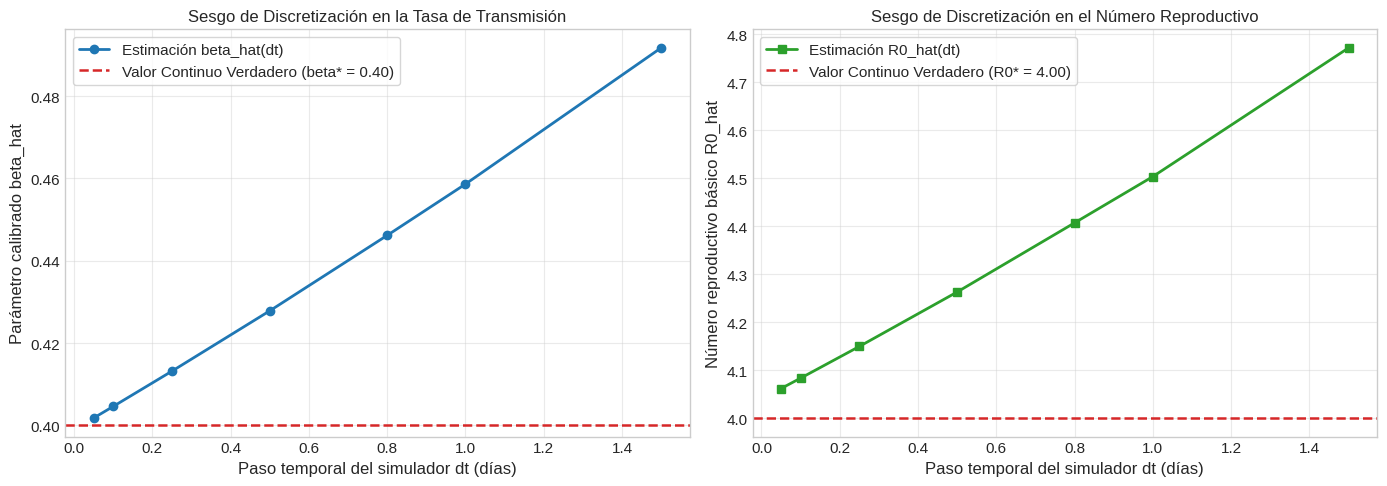

In [11]:
dt_valores = [0.05, 0.10, 0.25, 0.50, 0.80, 1.00, 1.50]
res_sesgo = experimento_sesgo_discretizacion(dt_valores, t_obs, I_obs)

beta_true = 0.40
gamma_true = 0.10
R0_true = 4.00

print("=" * 85)
print("SESGO DE DISCRETIZACIÓN EN LA CALIBRACIÓN INVERSA")
print(f"Parámetros verdaderos de referencia: beta* = {beta_true:.2f}, gamma* = {gamma_true:.2f}, R0* = {R0_true:.2f}")
print("=" * 85)
print(f"{'dt':>6s} | {'beta_hat':>10s} | {'gamma_hat':>10s} | {'R0_hat':>8s} | {'Error R0 (%)':>14s} | {'Pérdida':>10s}")
print("-" * 85)

for i in range(len(dt_valores)):
    dt_val = res_sesgo["dt"][i]
    b_h = res_sesgo["beta_hat"][i]
    g_h = res_sesgo["gamma_hat"][i]
    r0_h = res_sesgo["R0_hat"][i]
    err_r0 = ((r0_h - R0_true) / R0_true) * 100.0
    l_val = res_sesgo["loss"][i]
    print(f"{dt_val:6.2f} | {b_h:10.4f} | {g_h:10.4f} | {r0_h:8.4f} | {err_r0:+13.2f}% | {l_val:10.5f}")
print("=" * 85)

# Gráficas de análisis de sesgo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: beta_hat vs dt
axes[0].plot(res_sesgo["dt"], res_sesgo["beta_hat"], 'o-', color="#1f77b4", linewidth=2.0, markersize=6, label="Estimación beta_hat(dt)")
axes[0].axhline(beta_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (beta* = {beta_true:.2f})")
axes[0].set_title("Sesgo de Discretización en la Tasa de Transmisión")
axes[0].set_xlabel("Paso temporal del simulador dt (días)")
axes[0].set_ylabel("Parámetro calibrado beta_hat")
axes[0].legend(frameon=True)

# Panel 2: R0_hat vs dt
axes[1].plot(res_sesgo["dt"], res_sesgo["R0_hat"], 's-', color="#2ca02c", linewidth=2.0, markersize=6, label="Estimación R0_hat(dt)")
axes[1].axhline(R0_true, color="#d62728", linestyle="--", linewidth=1.8, label=f"Valor Continuo Verdadero (R0* = {R0_true:.2f})")
axes[1].set_title("Sesgo de Discretización en el Número Reproductivo")
axes[1].set_xlabel("Paso temporal del simulador dt (días)")
axes[1].set_ylabel("Número reproductivo básico R0_hat")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()


## 7. Reflexiones para la Salud Pública y Cierre Metodológico del Taller

### Impacto Sanitario: Cálculo del Umbral de Inmunidad Colectiva

Los resultados computacionales revelan que al aumentar el paso temporal $\Delta t$ de $0.05$ a $1.50$ días, el optimizador eleva sistemáticamente $\hat{\beta}$ de $0.4018$ a $0.4918$, inflando $\hat{R}_0$ de $4.06$ a $4.77$ (un error relativo del $+19.3\%$ atribuible únicamente a la malla numérica).

En epidemiología teórica, la proporción crítica de la población que debe ser inmunizada mediante vacunación para extinguir la transmisión comunitaria (inmunidad de rebaño) se calcula como:

$$p_c = 1 - \frac{1}{R_0}$$

Comparando las implicaciones de política pública:
- Con el parámetro verdadero continuo ($R_0^* = 4.00$):
  $$p_c = 1 - \frac{1}{4.00} = 0.750 \implies 75.0\%$$
- Con el parámetro sesgado por discretización gruesa a $\Delta t = 1.50$ ($\hat{R}_0 = 4.77$):
  $$p_c = 1 - \frac{1}{4.77} = 0.790 \implies 79.0\%$$

Una discrepancia de $4.0\%$ en una población nacional de 5 millones de habitantes representa **200,000 personas adicionales que el Ministerio de Salud planificaría vacunar innecesariamente**, o por el contrario, la imposición de cuarentenas más prolongadas basadas en una velocidad de contagio artificialmente sobreestimada.

El error numérico de discretización no es un detalle secundario de cómputo; distorsiona las inferencias científicas y tiene consecuencias directas y tangibles en las decisiones de salud pública.

### Cierre Metodológico del Taller

A lo largo de estos cuatro laboratorios, hemos recorrido la cadena completa de modelamiento matemático computacional:
1. **Discretización de EDOs**: Aprendimos a formular e implementar esquemas explícitos, implícitos e IMEX, identificando que el balance de masa físico y las cotas de estabilidad del paso temporal $\Delta t$ determinan la viabilidad de una simulación.
2. **Resolución de Sistemas No Lineales**: Vimos cómo los métodos implícitos conducen a problemas de búsqueda de raíces y cómo resolverlos eficientemente con herramientas científicas (`scipy.optimize.root`).
3. **Incertidumbre y Modelamiento Directo**: Construimos un laboratorio *in silico*, muestreamos a tiempos de reporte clínico y caracterizamos estadísticamente el ruido instrumental mediante residuos observacionales.
4. **Minimización de Funciones y Problemas Inversos**: Formulamos la función de pérdida por mínimos cuadrados y calibramos parámetros epidemiológicos mediante optimización libre de derivadas (`scipy.optimize.minimize` con Nelder-Mead), descubriendo que la malla de discretización temporal puede inducir sesgos sistemáticos capaces de distorsionar decisiones críticas en políticas públicas.
